In [1]:

%matplotlib inline
## 作用是在Notebook中直接显示Matplotlib生成的图表，而不是在弹出的窗口中显示。
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical ## 从torch.distributions模块中导入Categorical类，用于处理离散概率分布。
from tqdm.auto import tqdm ## 从tqdm.notebook模块中导入tqdm函数，用于在Notebook中显示进度条。

from IPython import display
import random

seed = 543 # Do not change this
def fix(env, seed):
  env.reset(seed=seed)
  env.action_space.seed(seed)
  env.observation_space.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
  np.random.seed(seed)
  random.seed(seed)
  torch.backends.cudnn.benchmark = False
  torch.backends.cudnn.deterministic = True
    

c:\Users\zhuxu\anaconda3\envs\ml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%%capture
import gymnasium
import random
import numpy as np

env = gymnasium.make('LunarLander-v3', render_mode='rgb_array')

import time
start = time.time()



In [3]:
print(env.observation_space)
print(env.action_space)
initial_state = env.reset()
print(initial_state)
random_action = env.action_space.sample()
print(random_action)
observation, reward, terminated, truncated, info = env.step(random_action) ## 
print(terminated)
print(truncated) ## truncated是指由于达到最大时间步数而终止的情况。
print(observation)
print(reward)
print(info)

Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Discrete(4)
(array([-0.00313797,  1.4216607 , -0.3178601 ,  0.47735134,  0.00364294,
        0.07200014,  0.        ,  0.        ], dtype=float32), {})
1
False
False
[-0.0063405   1.4318304  -0.32547992  0.45196632  0.0088149   0.10344934
  0.          0.        ]
0.0879490447728142
{}


## 随机喷射

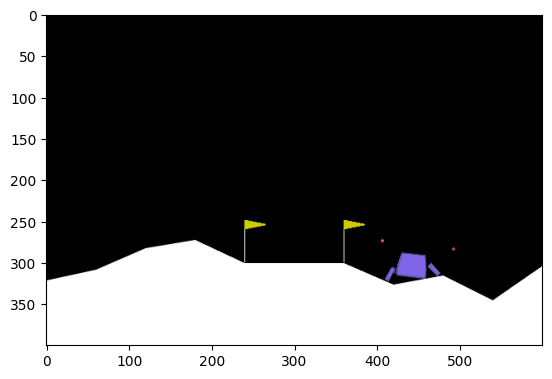

In [4]:
env.reset()
img = plt.imshow(env.render()) ## 以RGB数组的形式渲染环境，并使用Matplotlib的imshow函数显示图像。
done = False
while not done:
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    img.set_data(env.render())
    display.display(plt.gcf())
    display.clear_output(wait=True)
    done = terminated or truncated

# Policy Gradient Methods

In [ ]:
import math
import time
from tqdm.auto import tqdm
class PolicyGradientNetork(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(8,16)
        self.fc2 = nn.Linear(16,16)
        self.fc3 = nn.Linear(16,4)
    def forward(self, state):
        hid = torch.tanh(self.fc1(state))
        hid = torch.tanh(self.fc2(hid))
        return F.softmax(self.fc3(hid), dim=-1)

class PolicyGradientAgent:
    def __init__(self, netowrk):
        self.network = netowrk
        self.optimizer = optim.Adam(self.network.parameters(), lr=1e-3)
    def forward(self, state):
        return self.network(state)
    def learn(self, log_prob, reward):
        loss = (-log_prob * reward).mean() ## 计算损失函数，使用负的对数概率乘以奖励。这个损失函数的目标是最大化奖励。
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
    def sample(self, state, deterministic=False):
        action_prob = self.network(torch.FloatTensor(state)) 
        action_dist = Categorical(action_prob) ## 创建一个Categorical分布对象，表示动作的概率分布。
        if deterministic:
            action = torch.argmax(action_prob)
        else:
            action = action_dist.sample() ## 从动作概率分布中采样一个动作。
        log_prob = action_dist.log_prob(action)
        return action.item(), log_prob ## 返回采样的动作和对应的对数概率。
    
network = PolicyGradientNetork()
agent = PolicyGradientAgent(network)

agent.network.train()
EPISODE_PER_BATCH = 20  # 每蒐集 5 個 episodes 更新一次 agent
NUM_BATCH = 400 ## 总共训练400批次，每批次包含5个episodes。

gamma = 1 ## 折扣因子，用于计算未来奖励的现值。

avg_total_rewards = []
avg_final_rewards = []
prg_bar = tqdm(range(NUM_BATCH))
for i in prg_bar:
    rewards = []
    log_probs = []
    total_rewards = []
    final_rewards = []
    for episodde in range(EPISODE_PER_BATCH): ## 收集数据集
        state,info = env.reset()
        total_reward, total_step = 0, 0
        seq_rewards = []
        log_rewards = []
        while True:
            action, log_prob = agent.sample(state)
            next_state, reward, terminated, truncated, info = env.step(action)
            log_probs.append(log_prob)
            state = next_state
            seq_rewards.append(reward)
            total_reward += reward
            total_step += 1
            if terminated or truncated:
                final_rewards.append(reward)
                total_rewards.append(total_reward)
                break
        for t in range(total_step):
            reward_single = 0
            for k in range(t, total_step):
                reward_single += (gamma ** (k-t)) * seq_rewards[k] ## 计算从时间步t开始的未来奖励的现值。
            rewards.append(reward_single)
    print(f"rewards looks like ", np.shape(rewards))  
    print(f"log_probs looks like ", torch.stack(log_probs).shape) 
    avg_total_reward = sum(total_rewards) / len(total_rewards)
    avg_final_reward = sum(final_rewards) / len(final_rewards)
    avg_total_rewards.append(avg_total_reward)
    avg_final_rewards.append(avg_final_reward)
    prg_bar.set_description(f"Total: {avg_total_reward: 4.1f}, Final: {avg_final_reward: 4.1f}")
    
    rewards = (rewards - np.mean(rewards)) / (np.std(rewards) + 1e-9) ## 对奖励进行标准化处理，使其具有零均值和单位方差。
    agent.learn(torch.stack(log_probs), torch.from_numpy(rewards)) ## 使用收集到的对数概率和标准化后的奖励来更新策略网络。
    print("logs prob looks like ", torch.stack(log_probs).size())
    print("torch.from_numpy(rewards) looks like ", torch.from_numpy(rewards).size())
    
end = time.time()
plt.plot(avg_total_rewards)
plt.title("Total Rewards")
plt.show()
plt.plot(avg_final_rewards)
plt.title("Final Rewards")
plt.show()
        


Your reward is : -82.67
Your final reward is : -58.23
length of actions is  103


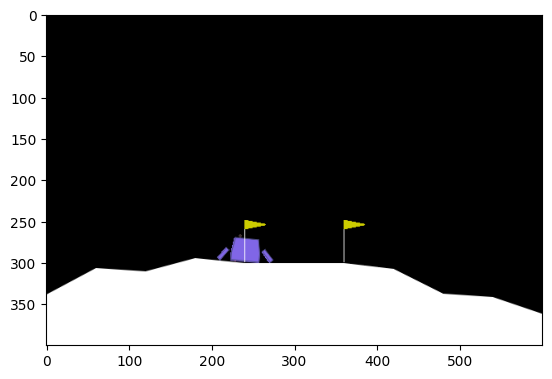

In [7]:
fix(env, seed)
agent.network.eval()  # 測試前先將 network 切換為 evaluation 模式
NUM_OF_TEST = 5 # Do not revise it !!!!!
test_total_reward = []
action_list = []
for i in range(NUM_OF_TEST):
  actions = []
  state,info = env.reset()

  img = plt.imshow(env.render())

  total_reward = 0

  done = False
  while not done:
      action, _ = agent.sample(state, deterministic=False) ## 在测试阶段，使用确定性策略，即选择概率最高的动作。
      actions.append(action)
      state, reward, terminated, truncated, info = env.step(action)

      total_reward += reward

      img.set_data(env.render())
      display.display(plt.gcf())       
      display.clear_output(wait=True)
      done = terminated or truncated
  print(f"Your reward is : %.2f"%total_reward)
  test_total_reward.append(total_reward)

  action_list.append(actions) #儲存你測試的結果
  print(f"Your final reward is : %.2f"%np.mean(test_total_reward))
  print("length of actions is ", len(actions))

# Actor-Critic Methods

In [6]:
from IPython import display
from tqdm.auto import tqdm
class RunningNorm:
    def __init__(self, dim, clip=5.0):
        self.mean = np.zeros(dim)
        self.var = np.ones(dim)
        self.count = 0
        self.clip = clip

    def update(self, x):
        self.count += 1
        alpha = 1 / self.count
        old_mean = self.mean.copy()
        self.mean = (1 - alpha) * self.mean + alpha * x
        self.var = (1 - alpha) * self.var + alpha * (x - old_mean) ** 2
    
    def normalize(self, x):
        std = np.sqrt(self.var + 1e-8)
        x = (x - self.mean) / std
        return np.clip(x, -self.clip, self.clip)

state_norm = RunningNorm(8)

class ActorCriticNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.share = nn.Sequential(
            nn.Linear(8,16),
            nn.Tanh(),
            nn.Linear(16,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh()
        )
        self.actor = nn.Linear(64,4)
        self.critic = nn.Linear(64,1)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
                nn.init.constant_(m.bias, 0)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)
        
    def forward(self, state):
        hid = self.share(state)
        actor = F.softmax(self.actor(hid), dim=-1)
        critic = self.critic(hid)
        return actor, critic
    def get_action(self, state, deterministic=False):
        action_prob, value = self.forward(state)
        action_dist = Categorical(action_prob)
        if deterministic:
            action = torch.argmax(action_prob,dim=-1)
        else:
            action = action_dist.sample() 
        log_prob = action_dist.log_prob(action)
        return action.item(), log_prob, value, action_prob



class ActorCriticAgent:
    def __init__(self, network):
        self.network = network
        self.optimizer = optim.Adam(self.network.parameters(), lr=1e-3)
    def sample(self, state, deterministic=False):
        state = state_norm.normalize(state)
        action, log_prob, value,action_prob = self.network.get_action(torch.FloatTensor(state), deterministic)
        return action, log_prob, value, action_prob
    def learn(self, log_prob, rewards, value, next_values, terminated, action_prob):
        returns = torch.zeros_like(rewards)
        advantages = torch.zeros_like(rewards)
        gae = 0
        for t in reversed(range(len(rewards))):
            if terminated[t] == 1:
                next_val = 0
                gae = 0
            else: 
                next_val = value[t+1] if t < len(rewards) - 1 else 0
            delta = rewards[t] + 0.99 * next_val - value[t]
            gae = delta + 0.99 * 0.95 * gae
            advantages[t] = gae
            returns[t] = advantages[t] + value[t]
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
        policy_loss = -(log_prob * advantages.detach()).mean()
        value_loss = F.mse_loss(value.squeeze(-1), returns)
        entropy_loss = 0.01 * (action_prob * torch.log(action_prob + 1e-8)).sum(dim=-1).mean()
        loss = policy_loss + 0.5 * value_loss + entropy_loss
        self.optimizer.zero_grad()
        loss.backward() 
        torch.nn.utils.clip_grad_norm_(self.network.parameters(), max_norm=0.5) ## 梯度裁剪，防止梯度爆炸。
        self.optimizer.step()
        
network = ActorCriticNetwork()
agent = ActorCriticAgent(network)

agent.network.train()
EPISODE_PER_BATCH = 5  # 每蒐集 5 個 episodes 更新一次 agent
NUM_BATCH = 400 ## 总共训练400批次，每批次包含5个episodes
avg_total_rewards = []
avg_final_rewards = []
prg_bar = tqdm(range(NUM_BATCH))
for i in prg_bar:
    rewards = []
    log_probs = []
    total_values = []
    total_next_values = []
    total_rewards = []
    final_rewards = []
    total_next_values = []
    total_terminated = []
    values = []
    next_values = []
    terminateds = []
    states = []
    action_probs = []
    for episodde in range(EPISODE_PER_BATCH): ## 收集数据集
        state,info = env.reset()
        total_reward, total_step = 0, 0
        seq_rewards = []
        while True:
            action, log_prob, value, action_prob = agent.sample(state)
            state_norm.update(state)
            values.append(value.squeeze(-1))
            next_state, reward, terminated, truncated, info = env.step(action)
            log_probs.append(log_prob)
            action_probs.append(action_prob)
            done = terminated or truncated
            terminateds.append(float(done))
            state = next_state
            seq_rewards.append(reward)
            total_reward += reward
            rewards.append(reward)
            total_step += 1
            if terminated or truncated:
                final_rewards.append(reward)
                total_rewards.append(total_reward)
                next_values.append(torch.tensor(0.0)) ## 如果episode结束了，下一个状态的价值估计为0。
                break
            if not terminated and not truncated:
                with torch.no_grad():
                    ns = state_norm.normalize(next_state)
                    next_value = agent.network.get_action(torch.FloatTensor(ns))[1] ## 获取下一个状态的价值估计。 
                next_values.append(next_value.squeeze(-1))
    avg_total_reward = sum(total_rewards) / len(total_rewards)
    avg_final_reward = sum(final_rewards) / len(final_rewards)
    avg_total_rewards.append(avg_total_reward)
    avg_final_rewards.append(avg_final_reward)
    prg_bar.set_description(f"Total: {avg_total_reward: 4.1f}, Final: {avg_final_reward: 4.1f}")
    agent.learn(torch.stack(log_probs), torch.tensor(rewards, dtype=torch.float32), torch.stack(values), torch.stack(next_values), torch.tensor(terminateds, dtype=torch.float32), torch.stack(action_probs)) ## 使用收集到的对数概率、标准化后的奖励和价值估计来更新策略网络和价值网络.

  0%|          | 0/400 [00:00<?, ?it/s]

Total: -296.3, Final: -100.0: 100%|██████████| 400/400 [05:13<00:00,  1.28it/s]


Your reward is : -621.51
Your final reward is : -849.08
length of actions is  100


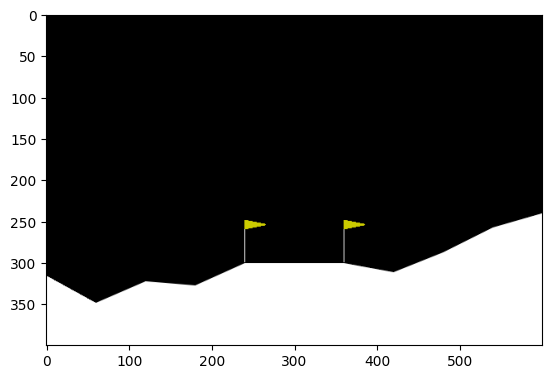

In [7]:
fix(env, seed)
agent.network.eval()  # 測試前先將 network 切換為 evaluation 模式
NUM_OF_TEST = 5 # Do not revise it !!!!!
test_total_reward = []
action_list = []
for i in range(NUM_OF_TEST):
  actions = []
  state,info = env.reset()

  img = plt.imshow(env.render())

  total_reward = 0

  done = False
  while not done:
      action, _ , _, _= agent.sample(state, deterministic=True) ## 在测试阶段，使用确定性策略，即选择概率最高的动作。
      actions.append(action)
      state, reward, terminated, truncated, info = env.step(action)

      total_reward += reward

      img.set_data(env.render())
      display.display(plt.gcf())       
      display.clear_output(wait=True)
      done = terminated or truncated
  print(f"Your reward is : %.2f"%total_reward)
  test_total_reward.append(total_reward)

  action_list.append(actions) #儲存你測試的結果
  print(f"Your final reward is : %.2f"%np.mean(test_total_reward))
  print("length of actions is ", len(actions))